# Séance 1 — Pandas & formats de géodonnées

## TP : explorer, enrichir et exporter un jeu de données spatial

Dans ce TP, on travaille en deux temps :

- **Partie 1 (guidée)** : on révise les bases de `pandas` (documentation, index, exploration, filtrage, tri, agrégation, valeurs manquantes, jointures) sur un petit jeu de 30 villes françaises, avec quelques mini-exercices.
- **Partie 2 (en autonomie)** : on vous donne 4 fichiers de sources différentes (CSV, JSON, GeoJSON, Parquet) décrivant 60 villes françaises — à vous de les charger, les nettoyer, les fusionner, en tirer des indicateurs, et les visualiser sur une carte, en réutilisant les notions vues en cours.

**Durée indicative : 2h30.**


## Installation des dépendances

Si vous n'avez pas encore créé et activé l'environnement virtuel du projet (voir le `README.md` à la racine), exécutez la cellule ci-dessous pour installer les packages nécessaires directement depuis ce notebook. Si votre environnement est déjà prêt, vous pouvez ignorer cette cellule.


In [1]:
%pip install -q -r ../../requirements.txt


Note: you may need to restart the kernel to use updated packages.


## Rappel : le pipeline data

On vient de voir en cours qu'un pipeline de traitement de données spatiales suit typiquement trois grandes étapes : **collecte** (récupérer la donnée brute — ici, on va la générer nous-mêmes), **validation** (vérifier qu'elle est cohérente : types, valeurs manquantes, valeurs aberrantes) et **transformation** (nettoyer, agréger, croiser avec d'autres sources). Aujourd'hui, on se concentre surtout sur la collecte et un peu de transformation avec `pandas` ; la validation en profondeur arrivera plus tard dans le module (séance 5-6).


In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)


## 1. Un premier jeu de données : les villes de France

On part d'une liste de 30 grandes villes françaises avec leur région, leurs coordonnées (latitude/longitude) et leur population. Ce n'est pas un fichier téléchargé : on le construit directement en Python, ce qui nous évite toute dépendance réseau pour cette première partie.


In [3]:
villes_data = [
    {"ville": "Paris", "region": "Île-de-France", "latitude": 48.8566, "longitude": 2.3522, "population": 2145000},
    {"ville": "Marseille", "region": "Provence-Alpes-Côte d'Azur", "latitude": 43.2965, "longitude": 5.3698, "population": 870000},
    {"ville": "Lyon", "region": "Auvergne-Rhône-Alpes", "latitude": 45.7640, "longitude": 4.8357, "population": 522000},
    {"ville": "Toulouse", "region": "Occitanie", "latitude": 43.6047, "longitude": 1.4442, "population": 493000},
    {"ville": "Nice", "region": "Provence-Alpes-Côte d'Azur", "latitude": 43.7102, "longitude": 7.2620, "population": 342000},
    {"ville": "Nantes", "region": "Pays de la Loire", "latitude": 47.2184, "longitude": -1.5536, "population": 314000},
    {"ville": "Montpellier", "region": "Occitanie", "latitude": 43.6108, "longitude": 3.8767, "population": 295000},
    {"ville": "Strasbourg", "region": "Grand Est", "latitude": 48.5734, "longitude": 7.7521, "population": 291000},
    {"ville": "Bordeaux", "region": "Nouvelle-Aquitaine", "latitude": 44.8378, "longitude": -0.5792, "population": 260000},
    {"ville": "Lille", "region": "Hauts-de-France", "latitude": 50.6292, "longitude": 3.0573, "population": 233000},
    {"ville": "Rennes", "region": "Bretagne", "latitude": 48.1173, "longitude": -1.6778, "population": 220000},
    {"ville": "Reims", "region": "Grand Est", "latitude": 49.2583, "longitude": 4.0317, "population": 182000},
    {"ville": "Le Havre", "region": "Normandie", "latitude": 49.4944, "longitude": 0.1079, "population": 170000},
    {"ville": "Saint-Étienne", "region": "Auvergne-Rhône-Alpes", "latitude": 45.4397, "longitude": 4.3872, "population": 172000},
    {"ville": "Toulon", "region": "Provence-Alpes-Côte d'Azur", "latitude": 43.1242, "longitude": 5.9280, "population": 171000},
    {"ville": "Grenoble", "region": "Auvergne-Rhône-Alpes", "latitude": 45.1885, "longitude": 5.7245, "population": 158000},
    {"ville": "Dijon", "region": "Bourgogne-Franche-Comté", "latitude": 47.3220, "longitude": 5.0415, "population": 156000},
    {"ville": "Angers", "region": "Pays de la Loire", "latitude": 47.4784, "longitude": -0.5632, "population": 152000},
    {"ville": "Nîmes", "region": "Occitanie", "latitude": 43.8367, "longitude": 4.3601, "population": 150000},
    {"ville": "Villeurbanne", "region": "Auvergne-Rhône-Alpes", "latitude": 45.7667, "longitude": 4.8794, "population": 149000},
    {"ville": "Clermont-Ferrand", "region": "Auvergne-Rhône-Alpes", "latitude": 45.7772, "longitude": 3.0870, "population": 147000},
    {"ville": "Le Mans", "region": "Pays de la Loire", "latitude": 48.0061, "longitude": 0.1996, "population": 143000},
    {"ville": "Aix-en-Provence", "region": "Provence-Alpes-Côte d'Azur", "latitude": 43.5297, "longitude": 5.4474, "population": 143000},
    {"ville": "Brest", "region": "Bretagne", "latitude": 48.3904, "longitude": -4.4861, "population": 139000},
    {"ville": "Tours", "region": "Centre-Val de Loire", "latitude": 47.3941, "longitude": 0.6848, "population": 136000},
    {"ville": "Amiens", "region": "Hauts-de-France", "latitude": 49.8941, "longitude": 2.2957, "population": 133000},
    {"ville": "Limoges", "region": "Nouvelle-Aquitaine", "latitude": 45.8336, "longitude": 1.2611, "population": 131000},
    {"ville": "Annecy", "region": "Auvergne-Rhône-Alpes", "latitude": 45.8992, "longitude": 6.1294, "population": 128000},
    {"ville": "Perpignan", "region": "Occitanie", "latitude": 42.6887, "longitude": 2.8948, "population": 119000},
    {"ville": "Metz", "region": "Grand Est", "latitude": 49.1193, "longitude": 6.1757, "population": 116000},
]

df_villes = pd.DataFrame(villes_data)
df_villes


,ville,region,latitude,longitude,population
0,Paris,Île-de-France,48.8566,2.3522,2145000
1,Marseille,Provence-Alpes-Côte d'Azur,43.2965,5.3698,870000
2,Lyon,Auvergne-Rhône-Alpes,45.7640,4.8357,522000
3,Toulouse,Occitanie,43.6047,1.4442,493000
4,Nice,Provence-Alpes-Côte d'Azur,43.7102,7.2620,342000
5,Nantes,Pays de la Loire,47.2184,-1.5536,314000
6,Montpellier,Occitanie,43.6108,3.8767,295000
7,Strasbourg,Grand Est,48.5734,7.7521,291000
8,Bordeaux,Nouvelle-Aquitaine,44.8378,-0.5792,260000
9,Lille,Hauts-de-France,50.6292,3.0573,233000


### Lire la documentation d'une fonction

Chaque exemple de ce notebook n'illustre qu'un usage parmi beaucoup d'autres. Avant d'utiliser une fonction pandas, prenez le réflexe de consulter sa signature complète : dans Jupyter, `?nom_fonction` ouvre la docstring dans un panneau (interactif uniquement, sans effet dans un export statique du notebook), `Shift+Tab` en survolant un appel de fonction donne un aperçu rapide, et `help(...)` fonctionne partout, y compris en script classique.


In [4]:
help(pd.DataFrame.sort_values)


Help on function sort_values in module pandas.core.frame:

sort_values(
    self,
    by: 'IndexLabel',
    *,
    axis: 'Axis' = 0,
    ascending: 'bool | list[bool] | tuple[bool, ...]' = True,
    inplace: 'bool' = False,
    kind: 'SortKind' = 'quicksort',
    na_position: 'str' = 'last',
    ignore_index: 'bool' = False,
    key: 'ValueKeyFunc | None' = None
) -> 'DataFrame | None'
    Sort by the values along either axis.

    Parameters
    ----------
    by : str or list of str
        Name or list of names to sort by.

        - if `axis` is 0 or `'index'` then `by` may contain index
          levels and/or column labels.
        - if `axis` is 1 or `'columns'` then `by` may contain column
          levels and/or index labels.
    axis : "{0 or 'index', 1 or 'columns'}", default 0
         Axis to be sorted.
    ascending : bool or list of bool, default True
         Sort ascending vs. descending. Specify list for multiple sort
         orders.  If this is a list of bools, must

### L'index : l'essence du DataFrame

Chaque ligne porte une étiquette — l'index. Par défaut, c'est une suite d'entiers (un `RangeIndex`), mais ce n'est qu'un choix parmi d'autres. L'index est ce qui permet à pandas d'aligner, de fusionner et de sélectionner des données de façon fiable.


In [5]:
stations = pd.DataFrame({
    "ville": ["Paris", "Lyon", "Marseille"],
    "temperature_c": [12.4, 15.1, 18.7],
})
print(stations.index)

# .loc : sélection par étiquette -- .iloc : sélection par position
print(stations.loc[2, "ville"])
print(stations.iloc[2, 0])

# set_index() donne un nom explicite aux lignes ; reset_index() fait l'inverse
stations_idx = stations.set_index("ville")
print(stations_idx.loc["Marseille"])
stations_idx.reset_index()


RangeIndex(start=0, stop=3, step=1)
Marseille
Marseille
temperature_c    18.7
Name: Marseille, dtype: float64


,ville,temperature_c
0,Paris,12.4
1,Lyon,15.1
2,Marseille,18.7


### Explorer le DataFrame

Trois réflexes à avoir systématiquement en arrivant sur un nouveau jeu de données : `head()` pour voir un aperçu, `info()` pour les types et les valeurs manquantes, `describe()` pour les statistiques descriptives des colonnes numériques.


In [6]:
print(df_villes.head())
print()
df_villes.info()


       ville                      region  latitude  longitude  population
0      Paris               Île-de-France   48.8566     2.3522     2145000
1  Marseille  Provence-Alpes-Côte d'Azur   43.2965     5.3698      870000
2       Lyon        Auvergne-Rhône-Alpes   45.7640     4.8357      522000
3   Toulouse                   Occitanie   43.6047     1.4442      493000
4       Nice  Provence-Alpes-Côte d'Azur   43.7102     7.2620      342000

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ville       30 non-null     object 
 1   region      30 non-null     object 
 2   latitude    30 non-null     float64
 3   longitude   30 non-null     float64
 4   population  30 non-null     int64  
dtypes: float64(2), int64(1), object(2)
memory usage: 1.3+ KB


In [7]:
df_villes.describe()


,latitude,longitude,population
count,30.000000,30.000000,3.000000e+01
mean,46.388673,2.990863,2.926667e+05
std,2.330606,2.977015,3.841035e+05
min,42.688700,-4.486100,1.160000e+05
25%,44.086975,0.828875,1.430000e+05
50%,45.866400,3.481850,1.640000e+05
75%,48.322125,5.287725,2.832500e+05
max,50.629200,7.752100,2.145000e+06


### Filtrer, trier, grouper

Quelques opérations de base : sélectionner des lignes selon une condition (`df[condition]`), trier avec `sort_values`, et agréger par groupe avec `groupby`.


In [8]:
# Villes de plus de 200 000 habitants, triées par population décroissante
grandes_villes = df_villes[df_villes["population"] > 200_000].sort_values("population", ascending=False)
grandes_villes


,ville,region,latitude,longitude,population
0,Paris,Île-de-France,48.8566,2.3522,2145000
1,Marseille,Provence-Alpes-Côte d'Azur,43.2965,5.3698,870000
2,Lyon,Auvergne-Rhône-Alpes,45.7640,4.8357,522000
3,Toulouse,Occitanie,43.6047,1.4442,493000
4,Nice,Provence-Alpes-Côte d'Azur,43.7102,7.2620,342000
5,Nantes,Pays de la Loire,47.2184,-1.5536,314000
6,Montpellier,Occitanie,43.6108,3.8767,295000
7,Strasbourg,Grand Est,48.5734,7.7521,291000
8,Bordeaux,Nouvelle-Aquitaine,44.8378,-0.5792,260000
9,Lille,Hauts-de-France,50.6292,3.0573,233000


In [9]:
# Nombre de villes et population totale par région, triés par population totale décroissante
df_villes.groupby("region")["population"].agg(["count", "sum"]).sort_values("sum", ascending=False)


,count,sum
region,,
Île-de-France,1,2145000
Provence-Alpes-Côte d'Azur,4,1526000
Auvergne-Rhône-Alpes,6,1276000
Occitanie,4,1057000
Pays de la Loire,3,609000
Grand Est,3,589000
Nouvelle-Aquitaine,2,391000
Hauts-de-France,2,366000
Bretagne,2,359000


### 🧪 À vous de jouer

1. Filtrez les villes dont la population est **inférieure à 150 000** habitants, puis triez le résultat par latitude **décroissante** (du nord au sud).
2. Regroupez les villes par région : calculez le **nombre de villes** et la **population moyenne** par région, trié par nombre de villes décroissant.


In [10]:
# 1) Filtrer les villes de moins de 150 000 habitants, trier par latitude décroissante
petites_villes = df_villes[df_villes["population"] < 150_000].sort_values("latitude", ascending=False)

# 2) Regrouper par région : nombre de villes et population moyenne, trié par nb_villes décroissant
stats_region = (
    df_villes.groupby("region")
    .agg(nb_villes=("ville", "count"), population_moyenne=("population", "mean"))
    .sort_values("nb_villes", ascending=False)
)

petites_villes


,ville,region,latitude,longitude,population
25,Amiens,Hauts-de-France,49.8941,2.2957,133000
29,Metz,Grand Est,49.1193,6.1757,116000
23,Brest,Bretagne,48.3904,-4.4861,139000
21,Le Mans,Pays de la Loire,48.0061,0.1996,143000
24,Tours,Centre-Val de Loire,47.3941,0.6848,136000
27,Annecy,Auvergne-Rhône-Alpes,45.8992,6.1294,128000
26,Limoges,Nouvelle-Aquitaine,45.8336,1.2611,131000
20,Clermont-Ferrand,Auvergne-Rhône-Alpes,45.7772,3.0870,147000
19,Villeurbanne,Auvergne-Rhône-Alpes,45.7667,4.8794,149000
22,Aix-en-Provence,Provence-Alpes-Côte d'Azur,43.5297,5.4474,143000


## 2. Nettoyer et enrichir le jeu de données

En pratique, un jeu de données est rarement aussi propre que celui qu'on vient d'explorer, et l'information utile est souvent répartie sur plusieurs fichiers. On simule quelques valeurs manquantes pour s'entraîner à les repérer et les traiter — un avant-goût de la **validation**, approfondie en séance 5-6 — puis on enrichit nos villes avec un second jeu de données grâce à une **jointure** — on verra les quatre variantes (`inner`, `left`, `right`, `outer`).


In [11]:
# On simule quelques valeurs manquantes, comme on en rencontre souvent en pratique
df_test = df_villes.copy()
df_test.loc[[3, 17], "population"] = np.nan

print("Valeurs manquantes par colonne :")
print(df_test.isna().sum())

# Deux stratégies courantes : dropna() pour supprimer les lignes, fillna() pour remplacer
mediane_pop = df_test["population"].median()
df_test["population"] = df_test["population"].fillna(mediane_pop)
df_test.loc[[3, 17], ["ville", "population"]]


Valeurs manquantes par colonne :
ville         0
region        0
latitude      0
longitude     0
population    2
dtype: int64


,ville,population
3,Toulouse,164000.0
17,Angers,164000.0


### `value_counts()` : un piège classique

`value_counts()` compte les occurrences de chaque valeur d'une colonne — mais par défaut, elle **ignore silencieusement** les valeurs manquantes. Sur un petit exemple indépendant :


In [12]:
exemple = pd.Series([15.1, 18.7, 11.8, None, None])

print("Par défaut :")
print(exemple.value_counts())

print("\nAvec dropna=False :")
print(exemple.value_counts(dropna=False))


Par défaut :
15.1    1
18.7    1
11.8    1
Name: count, dtype: int64

Avec dropna=False :
NaN     2
15.1    1
18.7    1
11.8    1
Name: count, dtype: int64


À gauche, rien n'indique qu'il manque 2 valeurs : c'est l'erreur la plus fréquente avec cette fonction. Deux autres paramètres utiles : `normalize=True` (proportions plutôt que comptes) et `sort=False` (garde l'ordre d'apparition).


Pour aller plus loin, on croise nos villes avec un second jeu de données : la **superficie** de chaque région (en km²). On utilise `pd.merge` — l'équivalent pandas d'une jointure SQL — pour associer chaque ville à la superficie de sa région, puis on calcule une densité de population approximative.


In [13]:
superficies_region = pd.DataFrame({
    "region": [
        "Île-de-France", "Provence-Alpes-Côte d'Azur", "Auvergne-Rhône-Alpes",
        "Occitanie", "Pays de la Loire", "Grand Est", "Nouvelle-Aquitaine",
        "Hauts-de-France", "Bretagne", "Normandie", "Bourgogne-Franche-Comté",
        "Centre-Val de Loire",
    ],
    "superficie_km2": [
        12_011, 31_400, 69_711, 72_724, 32_082, 57_433,
        84_061, 31_813, 27_208, 29_907, 47_784, 39_151,
    ],
})

df_villes = df_villes.merge(superficies_region, on="region", how="left")

# Densité illustrative : population de nos 30 villes / superficie de la région
# (pas la population réelle de la région entière, donc à prendre comme un ordre de grandeur)
densite_region = (
    df_villes.groupby(["region", "superficie_km2"])["population"]
    .sum()
    .reset_index()
)
densite_region["densite_hab_km2"] = densite_region["population"] / densite_region["superficie_km2"]
densite_region.sort_values("densite_hab_km2", ascending=False)


,region,superficie_km2,population,densite_hab_km2
11,Île-de-France,12011,2145000,178.586296
10,Provence-Alpes-Côte d'Azur,31400,1526000,48.598726
9,Pays de la Loire,32082,609000,18.982607
0,Auvergne-Rhône-Alpes,69711,1276000,18.304141
8,Occitanie,72724,1057000,14.534404
2,Bretagne,27208,359000,13.194649
5,Hauts-de-France,31813,366000,11.504731
4,Grand Est,57433,589000,10.255428
6,Normandie,29907,170000,5.684288
7,Nouvelle-Aquitaine,84061,391000,4.651384


### 🧪 À vous de jouer

1. Identifiez la région la plus dense et la région la moins dense (utilisez `idxmax()` / `idxmin()` sur `densite_hab_km2`).
2. Comptez le nombre de villes par région grâce à `value_counts()`, trié par ordre décroissant.


In [14]:
region_plus_dense = densite_region.loc[densite_region["densite_hab_km2"].idxmax(), "region"]
region_moins_dense = densite_region.loc[densite_region["densite_hab_km2"].idxmin(), "region"]

nb_villes_region = df_villes["region"].value_counts()

print(region_plus_dense, "/", region_moins_dense)
nb_villes_region


Île-de-France / Bourgogne-Franche-Comté


region
Auvergne-Rhône-Alpes          6
Provence-Alpes-Côte d'Azur    4
Occitanie                     4
Pays de la Loire              3
Grand Est                     3
Nouvelle-Aquitaine            2
Hauts-de-France               2
Bretagne                      2
Île-de-France                 1
Normandie                     1
Bourgogne-Franche-Comté       1
Centre-Val de Loire           1
Name: count, dtype: int64

### Les autres types de jointure : `right` et `outer`

Jusqu'ici on a utilisé `how="left"`. Il existe aussi `how="inner"` (le comportement par défaut de `merge`), `how="right"` (symétrique de `left`) et `how="outer"` (garde tout des deux côtés). La différence ne se voit que lorsque les clés ne correspondent pas parfaitement des deux côtés — illustrons ça avec un petit exemple indépendant de nos villes.


In [15]:
capteurs = pd.DataFrame({
    "capteur_id": ["C1", "C2", "C3"],
    "ville": ["Paris", "Lyon", "Brest"],
})
mesures_recentes = pd.DataFrame({
    "capteur_id": ["C1", "C2", "C9"],
    "valeur": [21.4, 19.8, 15.0],
})

print("--- how='right' ---")
print(capteurs.merge(mesures_recentes, on="capteur_id", how="right"))

print("\n--- how='outer' ---")
print(capteurs.merge(mesures_recentes, on="capteur_id", how="outer"))


--- how='right' ---
  capteur_id  ville  valeur
0         C1  Paris    21.4
1         C2   Lyon    19.8
2         C9    NaN    15.0

--- how='outer' ---
  capteur_id  ville  valeur
0         C1  Paris    21.4
1         C2   Lyon    19.8
2         C3  Brest     NaN
3         C9    NaN    15.0


`how="right"` garde tout de `mesures_recentes` : C3 (sans mesure) disparaît, C9 (sans ville connue) reste avec un `NaN`. `how="outer"` garde absolument tout des deux tables : C3 et C9 apparaissent tous les deux, chacun avec un `NaN` là où il manque une correspondance.


### 🧪 À vous de jouer

Calculez la jointure `how="inner"` entre `capteurs` et `mesures_recentes`. Combien de lignes contient-elle, et pourquoi moins que pour `outer` ?


In [16]:
jointure_inner = capteurs.merge(mesures_recentes, on="capteur_id", how="inner")

jointure_inner


,capteur_id,ville,valeur
0,C1,Paris,21.4
1,C2,Lyon,19.8


## Partie 2 — En autonomie : les villes de France, version complète

Cette fois, on ne vous donne plus le code : seulement des **consignes** et des **cellules vides** à remplir. Vous êtes libres dans votre façon de faire, du moment que vous arrivez au résultat demandé — n'hésitez pas à consulter `help(...)`, les slides du cours, ou la documentation pandas / geopandas / plotly / folium.

On vous fournit 4 fichiers, chacun produit par un service différent, dans `data/` :

| Fichier | Format | Contenu |
|---|---|---|
| `villes_geo.geojson` | GeoJSON | `ville`, `region`, géométrie (point) |
| `villes_demographie.csv` | CSV | `ville`, `population`, `age_moyen` |
| `villes_economie.json` | JSON | `ville`, `pib_par_habitant` |
| `villes_climat.parquet` | Parquet | `ville`, `temperature_moyenne_c` |

Comme souvent en pratique, ces fichiers contiennent chacun quelques défauts (valeurs manquantes, voire pire) qu'il faudra repérer et traiter avant de pouvoir les exploiter sereinement.

La cellule suivante génère ces 4 fichiers (à exécuter une seule fois, vous n'avez rien à y modifier) — la suite du TP commence juste après.


In [17]:
# Génération des 4 fichiers sources pour la partie 2 (à exécuter une seule fois)
import geopandas as gpd

villes_supplementaires = [
    {"ville": "Orléans", "region": "Centre-Val de Loire", "latitude": 47.9029, "longitude": 1.9093, "population": 116000},
    {"ville": "Mulhouse", "region": "Grand Est", "latitude": 47.7508, "longitude": 7.3359, "population": 108000},
    {"ville": "Caen", "region": "Normandie", "latitude": 49.1829, "longitude": -0.3707, "population": 105000},
    {"ville": "Nancy", "region": "Grand Est", "latitude": 48.6921, "longitude": 6.1844, "population": 104000},
    {"ville": "Tourcoing", "region": "Hauts-de-France", "latitude": 50.7236, "longitude": 3.1612, "population": 97000},
    {"ville": "Roubaix", "region": "Hauts-de-France", "latitude": 50.6927, "longitude": 3.1746, "population": 96000},
    {"ville": "Avignon", "region": "Provence-Alpes-Côte d'Azur", "latitude": 43.9493, "longitude": 4.8055, "population": 92000},
    {"ville": "Créteil", "region": "Île-de-France", "latitude": 48.7904, "longitude": 2.4556, "population": 91000},
    {"ville": "Poitiers", "region": "Nouvelle-Aquitaine", "latitude": 46.5802, "longitude": 0.3404, "population": 88000},
    {"ville": "Versailles", "region": "Île-de-France", "latitude": 48.8014, "longitude": 2.1301, "population": 85000},
    {"ville": "Béziers", "region": "Occitanie", "latitude": 43.3444, "longitude": 3.2158, "population": 79000},
    {"ville": "Cherbourg-en-Cotentin", "region": "Normandie", "latitude": 49.6337, "longitude": -1.6222, "population": 78000},
    {"ville": "Pau", "region": "Nouvelle-Aquitaine", "latitude": 43.2951, "longitude": -0.3708, "population": 77000},
    {"ville": "La Rochelle", "region": "Nouvelle-Aquitaine", "latitude": 46.1603, "longitude": -1.1511, "population": 76000},
    {"ville": "Colmar", "region": "Grand Est", "latitude": 48.0794, "longitude": 7.3585, "population": 70000},
    {"ville": "Valence", "region": "Auvergne-Rhône-Alpes", "latitude": 44.9334, "longitude": 4.8924, "population": 64000},
    {"ville": "Quimper", "region": "Bretagne", "latitude": 47.9960, "longitude": -4.0972, "population": 63000},
    {"ville": "Troyes", "region": "Grand Est", "latitude": 48.2973, "longitude": 4.0744, "population": 61000},
    {"ville": "Chambéry", "region": "Auvergne-Rhône-Alpes", "latitude": 45.5646, "longitude": 5.9178, "population": 59000},
    {"ville": "Niort", "region": "Nouvelle-Aquitaine", "latitude": 46.3237, "longitude": -0.4583, "population": 58000},
    {"ville": "Vannes", "region": "Bretagne", "latitude": 47.6582, "longitude": -2.7608, "population": 53000},
    {"ville": "Bayonne", "region": "Nouvelle-Aquitaine", "latitude": 43.4929, "longitude": -1.4748, "population": 51000},
    {"ville": "Laval", "region": "Pays de la Loire", "latitude": 48.0698, "longitude": -0.7700, "population": 50000},
    {"ville": "Albi", "region": "Occitanie", "latitude": 43.9298, "longitude": 2.1480, "population": 49000},
    {"ville": "Belfort", "region": "Bourgogne-Franche-Comté", "latitude": 47.6379, "longitude": 6.8629, "population": 47000},
    {"ville": "Charleville-Mézières", "region": "Grand Est", "latitude": 49.7716, "longitude": 4.7199, "population": 46000},
    {"ville": "Châteauroux", "region": "Centre-Val de Loire", "latitude": 46.8107, "longitude": 1.6911, "population": 43000},
    {"ville": "Agen", "region": "Nouvelle-Aquitaine", "latitude": 44.2049, "longitude": 0.6212, "population": 33000},
    {"ville": "Auxerre", "region": "Bourgogne-Franche-Comté", "latitude": 47.7982, "longitude": 3.5728, "population": 33000},
    {"ville": "Épinal", "region": "Grand Est", "latitude": 48.1735, "longitude": 6.4500, "population": 31000},
]

df_base = pd.DataFrame(villes_data + villes_supplementaires)

rng2 = np.random.default_rng(7)

# PIB par habitant : un niveau de base par région (ordre de grandeur réaliste),
# un effet taille de ville, et un peu de bruit
pib_base_region = {
    "Île-de-France": 52000, "Auvergne-Rhône-Alpes": 33000, "Provence-Alpes-Côte d'Azur": 31000,
    "Grand Est": 29000, "Pays de la Loire": 30500, "Nouvelle-Aquitaine": 29500,
    "Occitanie": 28500, "Hauts-de-France": 25500, "Bretagne": 29000,
    "Normandie": 27500, "Bourgogne-Franche-Comté": 28000, "Centre-Val de Loire": 27500,
}
df_base["pib_par_habitant"] = (
    df_base["region"].map(pib_base_region)
    + np.log1p(df_base["population"]) * 300
    + rng2.normal(0, 1200, len(df_base))
).round(-2)

# Âge moyen : légèrement plus jeune dans les grandes villes (effet étudiant), + bruit
df_base["age_moyen"] = (
    45 - np.log1p(df_base["population"]) * 0.5 + rng2.normal(0, 1.2, len(df_base))
).round(1)

# Température moyenne annuelle : gradient nord/sud, + bruit
df_base["temperature_moyenne_c"] = (
    16.5 - 0.30 * (df_base["latitude"] - 43) + rng2.normal(0, 0.6, len(df_base))
).round(1)

# --- Quelques défauts de qualité, volontairement injectés ---

# Valeurs manquantes concentrées sur les petites villes (< 80 000 hab.),
# moins bien suivies statistiquement en pratique
petites = df_base.index[df_base["population"] < 80_000].to_numpy()
rng2.shuffle(petites)

idx_outlier = petites[0]
idx_nan_age = petites[1:6]
idx_nan_pib = petites[6:11]
idx_nan_temp = petites[11:16]
idx_nan_pop = petites[16:18]

df_base.loc[idx_nan_age, "age_moyen"] = np.nan
df_base.loc[idx_nan_pib, "pib_par_habitant"] = np.nan
df_base.loc[idx_nan_temp, "temperature_moyenne_c"] = np.nan
df_base.loc[idx_nan_pop, "population"] = np.nan

# Une valeur aberrante : un capteur de température visiblement déréglé
df_base.loc[idx_outlier, "temperature_moyenne_c"] = 55.3

# Un doublon de région dû à une faute de frappe (accent manquant)
df_base.loc[df_base["ville"] == "Créteil", "region"] = "Ile-de-France"

# --- Export vers 4 fichiers, un par "service" ---
gdf_geo = gpd.GeoDataFrame(
    df_base[["ville", "region"]],
    geometry=gpd.points_from_xy(df_base["longitude"], df_base["latitude"]),
    crs="EPSG:4326",
)
gdf_geo.to_file(DATA_DIR / "villes_geo.geojson", driver="GeoJSON")

df_base[["ville", "population", "age_moyen"]].to_csv(DATA_DIR / "villes_demographie.csv", index=False)
df_base[["ville", "pib_par_habitant"]].to_json(DATA_DIR / "villes_economie.json", orient="records", indent=2)
df_base[["ville", "temperature_moyenne_c"]].to_parquet(DATA_DIR / "villes_climat.parquet", index=False)

print("4 fichiers générés dans data/ :")
print("- villes_geo.geojson, villes_demographie.csv, villes_economie.json, villes_climat.parquet")
print(f"- {len(df_base)} villes au total")


4 fichiers générés dans data/ :
- villes_geo.geojson, villes_demographie.csv, villes_economie.json, villes_climat.parquet
- 60 villes au total


### A. Charger les 4 fichiers

Chargez chacun des 4 fichiers avec la fonction pandas / geopandas adaptée à son format, et affichez un aperçu (`head()`) de chacun.


In [18]:
gdf_geo = gpd.read_file(DATA_DIR / "villes_geo.geojson")
df_demo = pd.read_csv(DATA_DIR / "villes_demographie.csv")
df_eco = pd.read_json(DATA_DIR / "villes_economie.json")
df_climat = pd.read_parquet(DATA_DIR / "villes_climat.parquet")

print(gdf_geo.head())
print(df_demo.head())
print(df_eco.head())
print(df_climat.head())


       ville                      region                  geometry
0      Paris               Île-de-France  POINT (2.35220 48.85660)
1  Marseille  Provence-Alpes-Côte d'Azur  POINT (5.36980 43.29650)
2       Lyon        Auvergne-Rhône-Alpes  POINT (4.83570 45.76400)
3   Toulouse                   Occitanie  POINT (1.44420 43.60470)
4       Nice  Provence-Alpes-Côte d'Azur  POINT (7.26200 43.71020)
       ville  population  age_moyen
0      Paris   2145000.0       38.0
1  Marseille    870000.0       37.6
2       Lyon    522000.0       38.6
3   Toulouse    493000.0       37.0
4       Nice    342000.0       37.9
       ville  pib_par_habitant
0      Paris           56400.0
1  Marseille           35500.0
2       Lyon           36600.0
3   Toulouse           31400.0
4       Nice           34300.0
       ville  temperature_moyenne_c
0      Paris                   14.8
1  Marseille                   16.1
2       Lyon                   15.6
3   Toulouse                   15.1
4       Nice    

### B. Explorer et nettoyer chaque source

Pour chacun des 4 jeux de données :

1. Comptez les valeurs manquantes par colonne.
2. Choisissez une stratégie de traitement adaptée à chaque colonne (suppression ou remplacement) et appliquez-la.

Vérifiez aussi les valeurs **uniques** de la colonne `region` du fichier géographique : un problème de saisie s'y est glissé (deux libellés différents désignent en réalité la même région). Repérez-le et corrigez-le.


In [19]:
for nom, df in [("geo", gdf_geo), ("démographie", df_demo), ("économie", df_eco), ("climat", df_climat)]:
    print(f"--- {nom} ---")
    print(df.isna().sum())
    print()

# region : un doublon dû à une faute de frappe (accent manquant)
print(gdf_geo["region"].unique())
gdf_geo["region"] = gdf_geo["region"].replace("Ile-de-France", "Île-de-France")

# age_moyen, pib_par_habitant, temperature_moyenne_c : peu de valeurs manquantes
# -> remplacement par la médiane (robuste), pas de raison de perdre ces villes
df_demo["age_moyen"] = df_demo["age_moyen"].fillna(df_demo["age_moyen"].median())
df_eco["pib_par_habitant"] = df_eco["pib_par_habitant"].fillna(df_eco["pib_par_habitant"].median())
df_climat["temperature_moyenne_c"] = df_climat["temperature_moyenne_c"].fillna(df_climat["temperature_moyenne_c"].median())

# population manquante sur seulement 2 villes : difficile à estimer sans donnée de référence -> on supprime
df_demo = df_demo.dropna(subset=["population"])


--- geo ---
ville       0
region      0
geometry    0
dtype: int64

--- démographie ---
ville         0
population    2
age_moyen     5
dtype: int64

--- économie ---
ville               0
pib_par_habitant    5
dtype: int64

--- climat ---
ville                    0
temperature_moyenne_c    5
dtype: int64

['Île-de-France' "Provence-Alpes-Côte d'Azur" 'Auvergne-Rhône-Alpes'
 'Occitanie' 'Pays de la Loire' 'Grand Est' 'Nouvelle-Aquitaine'
 'Hauts-de-France' 'Bretagne' 'Normandie' 'Bourgogne-Franche-Comté'
 'Centre-Val de Loire' 'Ile-de-France']


*Choix retenus : remplacement par la médiane pour `age_moyen`, `pib_par_habitant` et `temperature_moyenne_c` (peu de valeurs manquantes, pas de raison de perdre ces villes) ; suppression des 2 lignes sans `population` (donnée difficile à estimer sans source de référence) ; correction du doublon `"Ile-de-France"` → `"Île-de-France"` (simple faute de frappe).*


### C. Fusionner les 4 sources

Combinez les 4 jeux de données nettoyés en une seule table, sur la clé commune `ville`. Réfléchissez au type de jointure (`inner` / `left` / `right` / `outer`) le plus adapté ici, et vérifiez qu'aucune ville n'a été perdue ou dupliquée de façon inattendue (comparez le nombre de lignes avant/après).

💡 Si vous avez supprimé des lignes pour nettoyer une des sources, une jointure `left` sur le référentiel géographique peut faire réapparaître des `NaN` pour ces villes-là : c'est normal, et c'est un bon réflexe de le vérifier.


In [20]:
df_villes_full = (
    gdf_geo
    .merge(df_demo, on="ville", how="left")
    .merge(df_eco, on="ville", how="left")
    .merge(df_climat, on="ville", how="left")
)

print("geo:", len(gdf_geo), "| demo:", len(df_demo), "| eco:", len(df_eco), "| climat:", len(df_climat))
print("fusion:", len(df_villes_full), "| NaN population après fusion:", df_villes_full["population"].isna().sum())

# Le left join sur le référentiel géographique a fait réapparaître des NaN pour les 2 villes
# supprimées plus haut : on les traite maintenant, avant de s'en servir pour les cartes
df_villes_full["population"] = df_villes_full["population"].fillna(df_villes_full["population"].median())

df_villes_full.head()


geo: 60 | demo: 58 | eco: 60 | climat: 60
fusion: 60 | NaN population après fusion: 2


,ville,region,geometry,population,age_moyen,pib_par_habitant,temperature_moyenne_c
0,Paris,Île-de-France,POINT (2.35220 48.85660),2145000.0,38.0,56400.0,14.8
1,Marseille,Provence-Alpes-Côte d'Azur,POINT (5.36980 43.29650),870000.0,37.6,35500.0,16.1
2,Lyon,Auvergne-Rhône-Alpes,POINT (4.83570 45.76400),522000.0,38.6,36600.0,15.6
3,Toulouse,Occitanie,POINT (1.44420 43.60470),493000.0,37.0,31400.0,15.1
4,Nice,Provence-Alpes-Côte d'Azur,POINT (7.26200 43.71020),342000.0,37.9,34300.0,15.6


### D. Découper la France en 4 quadrants

À partir de la géométrie, retrouvez la latitude et la longitude de chaque ville (`geometry.y` / `geometry.x`). Calculez la latitude et la longitude **médianes** de l'ensemble des villes, puis créez une colonne `quadrant` (`"Nord-Ouest"`, `"Nord-Est"`, `"Sud-Ouest"`, `"Sud-Est"`) à l'aide d'une fonction personnalisée appliquée ligne à ligne (cf. slides : « Filtrer / créer une colonne avec une fonction personnalisée »).


In [21]:
df_villes_full["latitude"] = df_villes_full.geometry.y
df_villes_full["longitude"] = df_villes_full.geometry.x

lat_mediane = df_villes_full["latitude"].median()
lon_mediane = df_villes_full["longitude"].median()

def quadrant(row):
    if row["latitude"] >= lat_mediane:
        return "Nord-Ouest" if row["longitude"] < lon_mediane else "Nord-Est"
    else:
        return "Sud-Ouest" if row["longitude"] < lon_mediane else "Sud-Est"

df_villes_full["quadrant"] = df_villes_full.apply(quadrant, axis=1)
df_villes_full["quadrant"].value_counts()


quadrant
Nord-Ouest    17
Sud-Est       17
Sud-Ouest     13
Nord-Est      13
Name: count, dtype: int64

### E. Calculer des indicateurs agrégés

Avant de conclure quoi que ce soit, regardez les statistiques descriptives (`describe()`) de vos indicateurs : une valeur de température vous semble-t-elle physiquement impossible pour la France ? Traitez-la comme vous traiteriez une valeur manquante.

Ensuite, pour chaque **quadrant**, puis pour chaque **région**, calculez en une seule fois (`agg`) : population totale, PIB par habitant moyen, âge moyen, température moyenne, et nombre de villes. Triez les résultats par population totale décroissante.


In [22]:
df_villes_full[["population", "pib_par_habitant", "age_moyen", "temperature_moyenne_c"]].describe()


,population,pib_par_habitant,age_moyen,temperature_moyenne_c
count,6.000000e+01,60.00000,58.000000,60.000000
mean,1.837000e+05,33845.00000,38.998276,15.881667
std,2.914279e+05,5500.15177,1.016270,5.241765
min,3.100000e+04,28000.00000,36.600000,13.700000
25%,7.675000e+04,31475.00000,38.525000,14.700000
50%,1.175000e+05,33000.00000,38.900000,15.000000
75%,1.610000e+05,34325.00000,39.700000,15.625000
max,2.145000e+06,56500.00000,41.000000,55.300000


In [23]:
# Une température de 55.3°C est physiquement impossible en France : on la traite comme une valeur manquante
mediane_temp = df_villes_full.loc[df_villes_full["temperature_moyenne_c"] < 40, "temperature_moyenne_c"].median()
df_villes_full.loc[df_villes_full["temperature_moyenne_c"] > 40, "temperature_moyenne_c"] = mediane_temp

kpi_quadrant = (
    df_villes_full.groupby("quadrant")
    .agg(
        nb_villes=("ville", "count"),
        population_totale=("population", "sum"),
        pib_moyen=("pib_par_habitant", "mean"),
        age_moyen=("age_moyen", "mean"),
        temperature_moyenne=("temperature_moyenne_c", "mean"),
    )
    .sort_values("population_totale", ascending=False)
)
print(kpi_quadrant.round(1))

kpi_region = (
    df_villes_full.groupby("region")
    .agg(
        nb_villes=("ville", "count"),
        population_totale=("population", "sum"),
        pib_moyen=("pib_par_habitant", "mean"),
        age_moyen=("age_moyen", "mean"),
        temperature_moyenne=("temperature_moyenne_c", "mean"),
    )
    .sort_values("population_totale", ascending=False)
)
kpi_region.round(1)


            nb_villes  population_totale  pib_moyen  age_moyen  \
quadrant                                                         
Nord-Ouest         17          4179500.0    35982.4       38.8   
Sud-Est            17          3697000.0    34076.5       39.0   
Sud-Ouest          13          1792000.0    32446.2       38.8   
Nord-Est           13          1353500.0    32146.2       39.6   

            temperature_moyenne  
quadrant                         
Nord-Ouest                 14.6  
Sud-Est                    15.7  
Sud-Ouest                  15.8  
Nord-Est                   14.7  


,nb_villes,population_totale,pib_moyen,age_moyen,temperature_moyenne
region,,,,,
Île-de-France,3,2321000.0,56066.7,38.2,14.5
Provence-Alpes-Côte d'Azur,5,1618000.0,34360.0,38.6,16.1
Auvergne-Rhône-Alpes,8,1399000.0,35287.5,39.2,15.6
Occitanie,6,1185000.0,31816.7,39.1,15.7
Grand Est,9,1080500.0,32877.8,39.3,14.9
Nouvelle-Aquitaine,8,774000.0,32800.0,38.8,15.8
Pays de la Loire,4,726500.0,33550.0,38.6,15.0
Hauts-de-France,4,559000.0,28875.0,38.8,14.1
Bretagne,4,475000.0,33175.0,39.6,14.7


*Exemple d'observations : l'Île-de-France se détache nettement avec un PIB par habitant très supérieur au reste du pays (effet Paris), tandis que les Hauts-de-France affichent le PIB par habitant le plus bas. Les quadrants Nord (Nord-Ouest, Nord-Est) sont nettement plus peuplés que les quadrants Sud, mais le Sud-Est et le Sud-Ouest profitent de températures moyennes plus élevées.*


### F. Exploration rapide avec `pandas.plot`

Produisez 2 ou 3 graphiques rapides avec `.plot()` pour explorer vos indicateurs (par exemple : population par quadrant, PIB par habitant vs âge moyen, distribution de la température). L'objectif ici est la rapidité, pas l'esthétique.


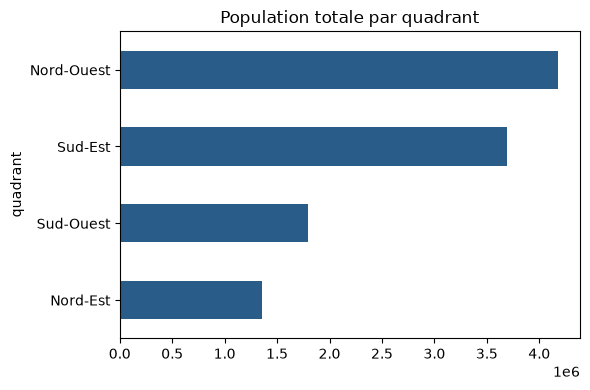

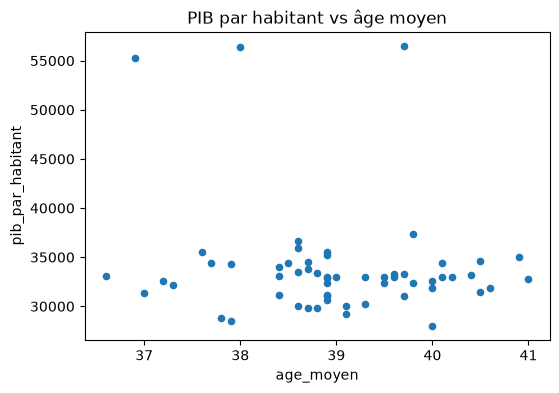

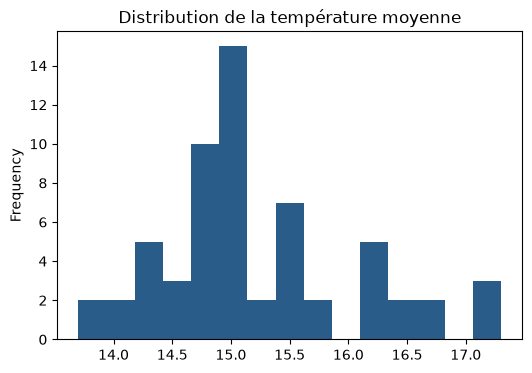

In [24]:
import matplotlib.pyplot as plt

kpi_quadrant["population_totale"].sort_values().plot(kind="barh", figsize=(6, 4), color="#2A5C8A")
plt.title("Population totale par quadrant")
plt.tight_layout()
plt.show()

df_villes_full.plot(kind="scatter", x="age_moyen", y="pib_par_habitant", figsize=(6, 4))
plt.title("PIB par habitant vs âge moyen")
plt.show()

df_villes_full["temperature_moyenne_c"].plot(kind="hist", bins=15, figsize=(6, 4), color="#2A5C8A")
plt.title("Distribution de la température moyenne")
plt.show()


### G. Carte interactive avec Plotly

Créez une carte Plotly (`scatter_geo` ou équivalent) de vos 60 villes : la couleur représente le quadrant (ou une région), la taille un indicateur de votre choix (population, PIB...), et l'info-bulle (`hover_name` / `hover_data`) donne le détail par ville. Exportez-la en HTML (`fig.write_html(...)`).


In [25]:
import plotly.express as px

fig = px.scatter_geo(
    df_villes_full, lat="latitude", lon="longitude",
    color="quadrant", size="population", hover_name="ville",
    hover_data={"pib_par_habitant": True, "age_moyen": True, "temperature_moyenne_c": True},
    scope="europe", title="Villes de France par quadrant",
)
fig.write_html(DATA_DIR / "carte_villes_plotly.html")
fig.show()


### H. Carte interactive avec Folium

Créez une carte Folium : un marqueur par ville, coloré selon le quadrant (ou la région), avec une info dans le popup (nom, population, indicateur de votre choix). Exportez-la en HTML (`carte.save(...)`).


In [26]:
import folium

couleurs_quadrant = {
    "Nord-Ouest": "#2A5C8A", "Nord-Est": "#8A2A5C",
    "Sud-Ouest": "#5C8A2A", "Sud-Est": "#8A5C2A",
}

carte = folium.Map(location=[46.6, 2.5], zoom_start=6)

for _, row in df_villes_full.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=max(3, row["population"] / 100_000),
        popup=(
            f"{row['ville']} ({row['quadrant']})<br>"
            f"Population : {row['population']:,.0f} hab.<br>"
            f"PIB/hab : {row['pib_par_habitant']:,.0f} €"
        ),
        color=couleurs_quadrant[row["quadrant"]],
        fill=True,
        fill_opacity=0.7,
    ).add_to(carte)

carte.save(DATA_DIR / "carte_villes_folium.html")
carte


### I. Conclusion

En 3 à 5 phrases : que retenez-vous de la comparaison entre quadrants / régions ? Et pour quel usage choisiriez-vous `pandas.plot`, Plotly ou Folium (exploration personnelle, rapport, diffusion web) ?

*Exemple de réponse : la richesse (PIB/habitant) est avant tout un effet régional (Île-de-France) plus que géographique Nord/Sud, alors que la température suit un vrai gradient Nord/Sud. `pandas.plot` reste le bon réflexe pour une exploration rapide et jetable ; Plotly est préférable pour un rapport interactif partagé par lien HTML ; Folium est idéal quand le fond de carte géographique précis (rues, relief) apporte une information en soi.*


## Ce qu'on a vu aujourd'hui

- Les bases de `pandas` pour explorer un jeu de données tabulaire : `head`, `info`, `describe`, filtrage, tri, `groupby`.
- Comment lire la documentation d'une fonction (`help`, `?`, Shift+Tab) et pourquoi l'index (`.loc`/`.iloc`, `set_index`/`reset_index`) est au cœur du DataFrame.
- Comment repérer et traiter des valeurs manquantes (`isna`, `dropna`, `fillna`), des valeurs aberrantes, et des doublons de catégorie dus à des erreurs de saisie.
- Comment enrichir un jeu de données par jointure avec `pd.merge` (`inner`/`left`/`right`/`outer`), l'équivalent pandas des `JOIN` SQL — y compris en fusionnant 4 sources de formats différents (CSV, JSON, GeoJSON, Parquet).
- Comment créer une colonne dérivée avec une fonction personnalisée (ici, un découpage géographique en quadrants).
- Comment calculer plusieurs agrégations à la fois avec `agg`, pour comparer des indicateurs entre groupes.
- Comment visualiser rapidement des données avec `pandas.plot()`, puis produire des cartes interactives diffusables avec `Plotly` et `folium` (export HTML).

**La semaine prochaine (séance 2)** : on quitte les fichiers locaux pour aller chercher de la donnée via des APIs — on construira notre propre micro-API avant d'interroger une vraie API publique (USGS, séismes).
